# QFF 2026 — Universal Processor A/B Architecture Benchmark

This notebook orchestrates the shared code in `src/` to characterize the five-logical-qubit weighted ZZ workload on Processor A and Processor B. It regenerates the raw six-case simulation results, validates the evidence, and creates the analysis tables and figures.

**Scope boundary:** this neutral architecture/routing workload is not a quantum implementation of the PS-P1 ECDH + ML-KEM key exchange. The classical cryptographic benchmark remains a separate experiment. All quantum noise results below are simulated with the prescribed synthetic noise model, not measured hardware results.

Run every cell from top to bottom in a clean Python kernel. The canonical results are written to `data/raw/`, `data/processed/`, and `results/`.

## 1. Environment and repository setup

In [1]:
from pathlib import Path
import os
import platform
import sys
from importlib.metadata import PackageNotFoundError, version

# Locate the repository even if the notebook server started in a subdirectory.
_cwd = Path.cwd().resolve()
_candidates = [_cwd, *_cwd.parents]
REPO_ROOT = next(
    (p for p in _candidates if (p / "src" / "problem.py").is_file()
     and (p / "processors").is_dir()),
    None,
)
if REPO_ROOT is None:
    raise RuntimeError(
        "Open/run this notebook from inside the SRM-Qiskit-FF-PS-P1 repository."
    )
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import qiskit
import qiskit_aer
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib
from IPython.display import display, Image, Markdown


def _version(distribution):
    try:
        return version(distribution)
    except PackageNotFoundError:
        return "not installed"

environment = {
    "repository_root": str(REPO_ROOT),
    "python": sys.version,
    "os": platform.platform(),
    "architecture": platform.machine(),
    "qiskit": qiskit.__version__,
    "qiskit_aer": qiskit_aer.__version__,
    "networkx": nx.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "liboqs-python": _version("liboqs-python"),
}
display(pd.DataFrame([{"component": k, "version_or_value": v} for k, v in environment.items()]))

,component,version_or_value
0,repository_root,D:\Vasisht\SRM-Qiskit-FF-PS-P1
1,python,"3.13.16 (main, Oct 14 2026, 01:05:56) [MSC v.1..."
2,os,Windows-11-10.0.26300-SP0
3,architecture,AMD64
4,qiskit,2.5.2
5,qiskit_aer,0.17.2
6,networkx,3.7
7,numpy,2.5.4
8,pandas,3.0.6
9,matplotlib,3.11.2


## 2. Load and validate Processor A and B configurations

In [2]:
from src.processors import load_processor

processor_specs = {}
processor_graphs = {}
processor_coupling_maps = {}
processor_noise_models = {}
configuration_rows = []

for processor_id, expected_qubits in (("A", 5), ("B", 9)):
    config_path = REPO_ROOT / "processors" / f"processor_{processor_id}.json"
    spec, graph, coupling_map, noise_model = load_processor(config_path)
    assert spec["num_qubits"] == expected_qubits
    assert graph.number_of_nodes() == expected_qubits
    assert nx.is_connected(graph)
    assert len(spec["coupling_edges_undirected"]) == graph.number_of_edges()
    assert spec["basis_gates"] == ["rz", "sx", "x", "cx"]
    assert spec["transpilation"]["optimization_level"] == 1
    assert spec["transpilation"]["seed_transpiler"] == 42
    assert spec["transpilation"]["shots"] == 4096

    processor_specs[processor_id] = spec
    processor_graphs[processor_id] = graph
    processor_coupling_maps[processor_id] = coupling_map
    processor_noise_models[processor_id] = noise_model
    configuration_rows.append({
        "processor": spec["name"],
        "physical_qubits": spec["num_qubits"],
        "undirected_edges": graph.number_of_edges(),
        "basis_gates": ", ".join(spec["basis_gates"]),
        "optimization_level": spec["transpilation"]["optimization_level"],
        "transpiler_seed": spec["transpilation"]["seed_transpiler"],
        "shots": spec["transpilation"]["shots"],
        **spec["noise"],
    })

assert processor_specs["A"]["noise"] == processor_specs["B"]["noise"]
display(pd.DataFrame(configuration_rows))
print("Processor configuration checks: PASS")

,processor,physical_qubits,undirected_edges,basis_gates,optimization_level,transpiler_seed,shots,one_qubit_depolarizing_probability,cx_depolarizing_probability,readout_error_probability
0,Processor A,5,4,"rz, sx, x, cx",1,42,4096,0.001,0.005,0.01
1,Processor B,9,12,"rz, sx, x, cx",1,42,4096,0.001,0.005,0.01


Processor configuration checks: PASS


## 3. Processor coupling-map visualization

Saved coupling map: results\figures\coupling_maps.png


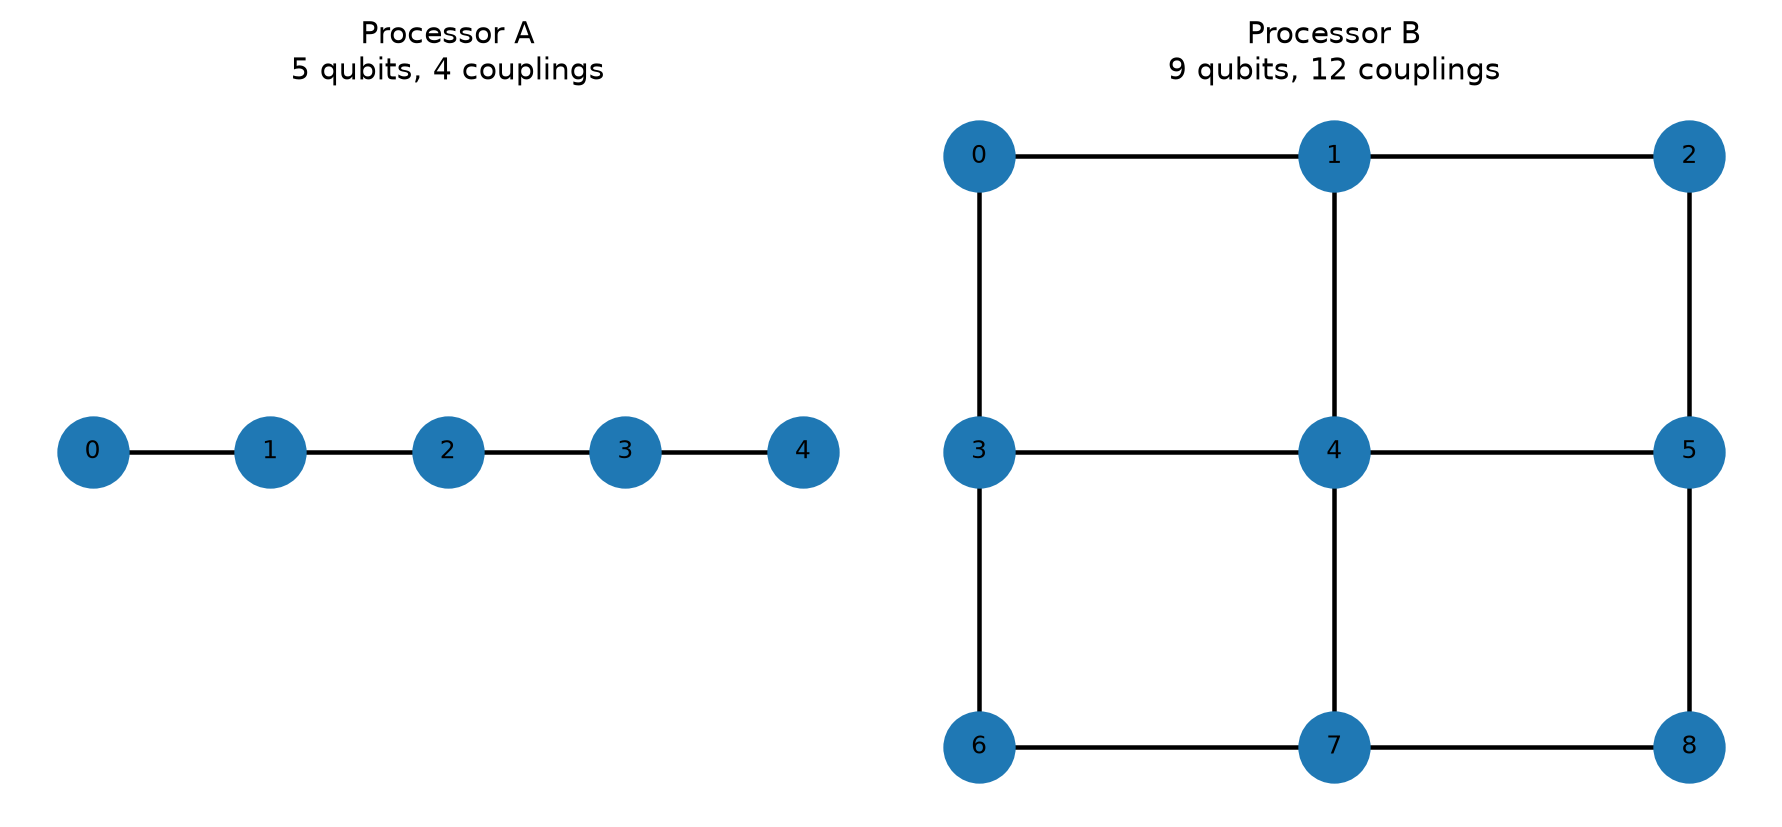

In [3]:
from src.visualization import plot_coupling_maps

coupling_map_path = plot_coupling_maps(
    REPO_ROOT / "processors",
    REPO_ROOT / "results" / "figures" / "coupling_maps.png",
)
print(f"Saved coupling map: {coupling_map_path.relative_to(REPO_ROOT)}")
display(Image(filename=str(coupling_map_path)))

## 4. Fixed logical workload and exact ideal references

In [4]:
from src.problem import (
    BETA,
    INTERACTIONS,
    N_LOGICAL_QUBITS,
    SUPPORTED_REPS,
    THETA,
    build_logical_circuit,
    build_zz_observable,
    ideal_reference,
)

reference_rows = []
for reps in SUPPORTED_REPS:
    logical_circuit = build_logical_circuit(reps, measure=False)
    state, expectation, ideal_probabilities = ideal_reference(reps)
    norm = float(np.vdot(state.data, state.data).real)
    probability_sum = sum(ideal_probabilities.values())
    assert np.isclose(norm, 1.0, atol=1e-10)
    assert np.isclose(probability_sum, 1.0, atol=1e-10)
    reference_rows.append({
        "reps": reps,
        "logical_qubits": logical_circuit.num_qubits,
        "logical_depth": logical_circuit.depth(),
        "interaction_terms": len(INTERACTIONS),
        "theta_radians": THETA,
        "beta_radians": BETA,
        "ideal_H_ZZ_expectation": expectation,
        "state_norm": norm,
        "probability_sum": probability_sum,
        "nonzero_ideal_outcomes": len(ideal_probabilities),
    })

display(pd.DataFrame(reference_rows))
print("Weighted ZZ observable:")
display(build_zz_observable())
print("Example logical circuit, reps=1:")
display(build_logical_circuit(1).draw(output="mpl", fold=-1))

,reps,logical_qubits,logical_depth,interaction_terms,theta_radians,beta_radians,ideal_H_ZZ_expectation,state_norm,probability_sum,nonzero_ideal_outcomes
0,1,5,8,7,0.37,0.23,0.886884,1.0,1.0,32
1,2,5,16,7,0.37,0.23,4.795849,1.0,1.0,32
2,3,5,24,7,0.37,0.23,2.993781,1.0,1.0,32


Weighted ZZ observable:


SparsePauliOp(['IIIZZ', 'IIZZI', 'IZZII', 'ZZIII', 'ZIIIZ', 'IIZIZ', 'IZIZI'],
              coeffs=[1. +0.j, 0.8+0.j, 1.2+0.j, 0.9+0.j, 1.1+0.j, 0.6+0.j, 0.7+0.j])

Example logical circuit, reps=1:


<Figure size 1458.05x451.5 with 1 Axes>

## 5. Transpilation, native metrics, and saved circuit diagrams

,processor,reps,logical_depth,transpiled_depth,physical_qubit_budget,native_CX_count,diagnostic_explicit_SWAPs,unconstrained_CX_count,extra_CX_count,SWAP_equivalent_CX_proxy
0,A,1,9,34,5,27,5,14,13,4.333333
1,A,2,17,78,5,62,12,28,34,11.333333
2,A,3,25,116,5,93,19,42,51,17.000000
3,B,1,9,30,9,17,1,14,3,1.000000
4,B,2,17,57,9,37,3,28,9,3.000000
5,B,3,25,84,9,57,5,42,15,5.000000


Saved logical diagrams: logical_reps_1.png, logical_reps_2.png, logical_reps_3.png
Saved six native-basis transpiled circuit diagrams.
Native-basis example for Processor A, reps=1:


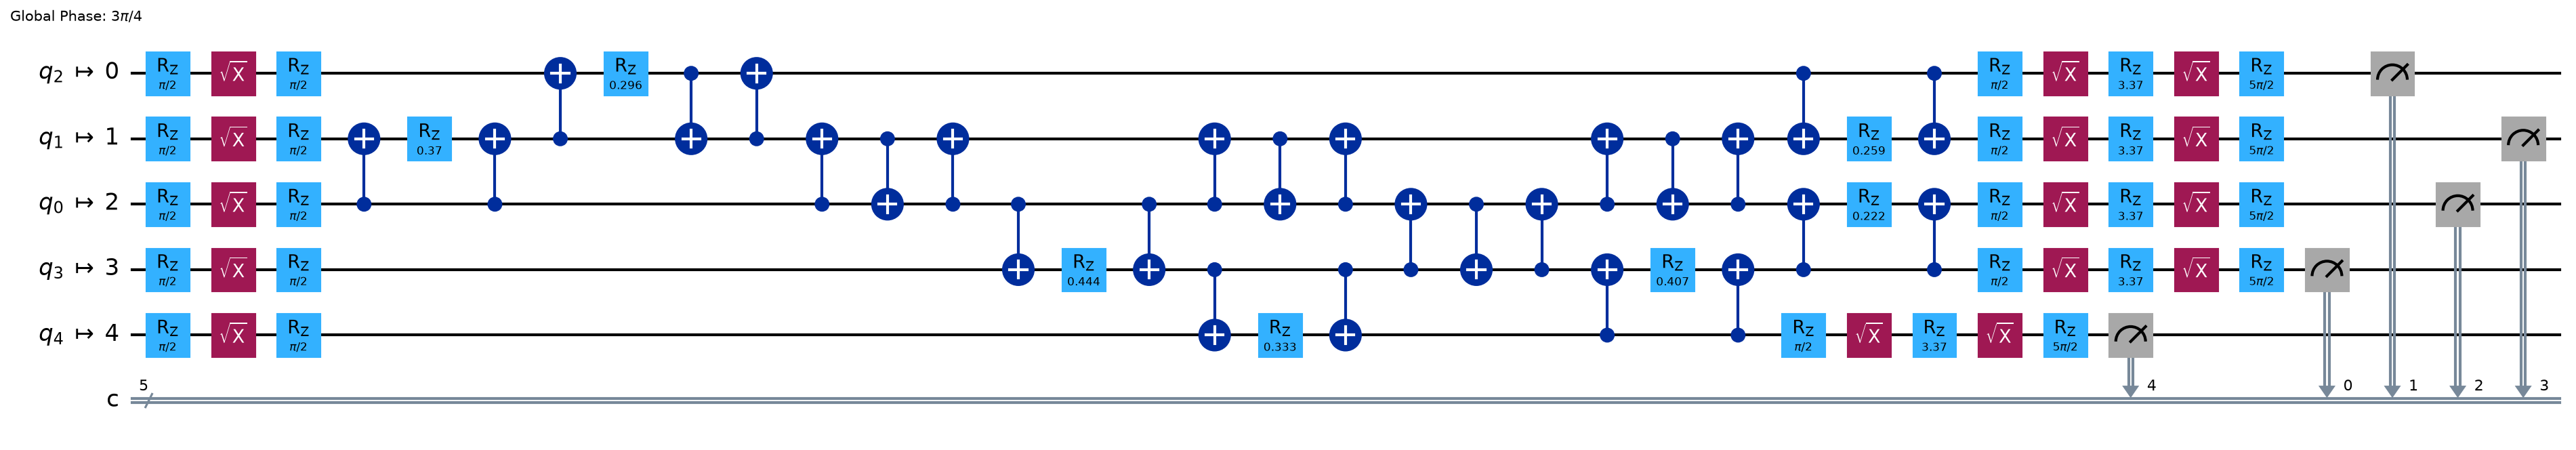

Native-basis example for Processor B, reps=1:


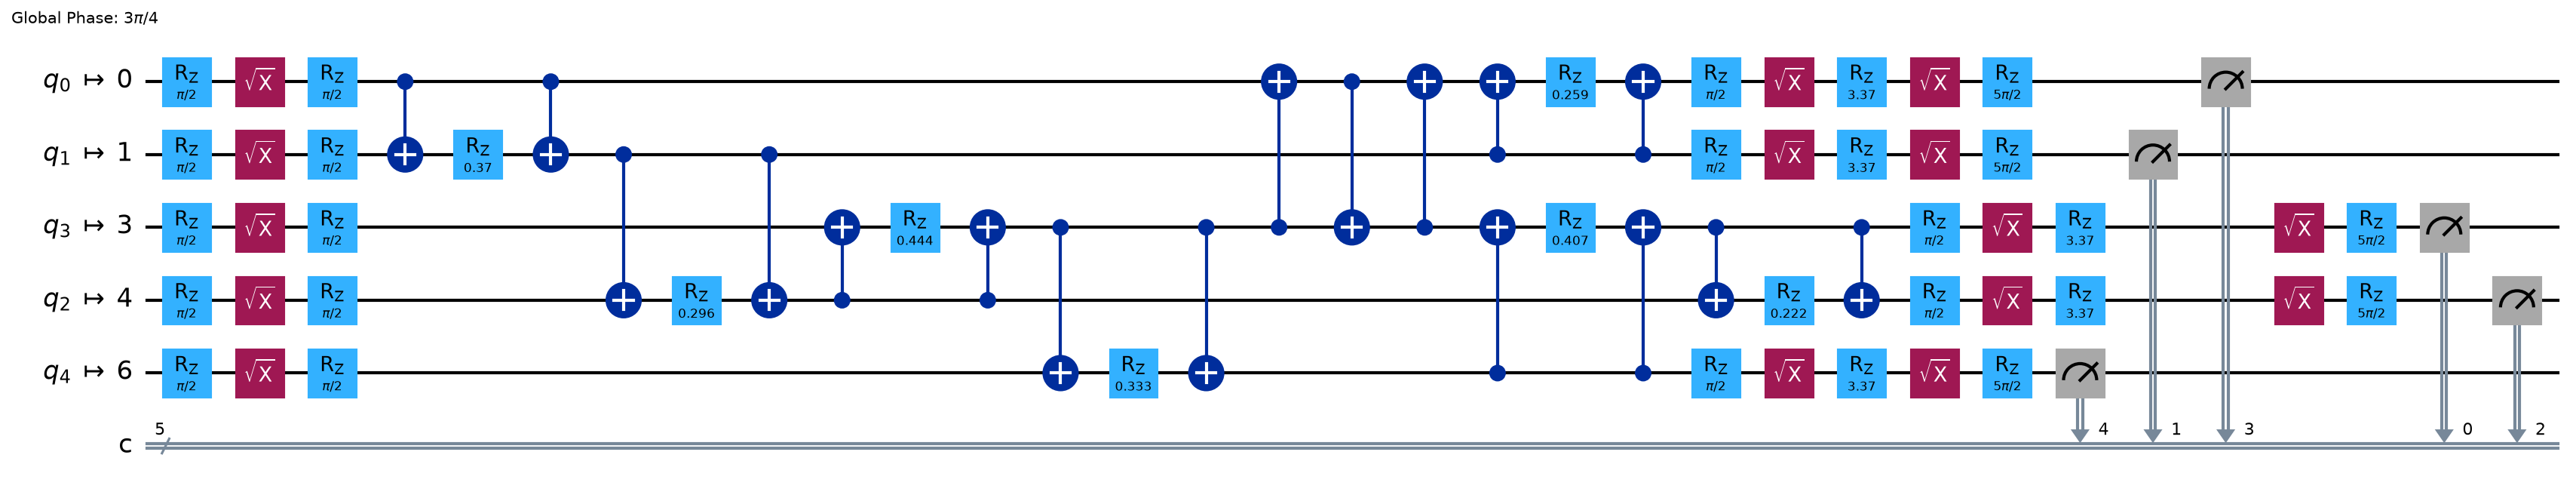

In [5]:
import matplotlib.pyplot as plt
from src.routing import compile_for_processor

figures_dir = REPO_ROOT / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Save one logical circuit diagram per repetition level.
for reps in SUPPORTED_REPS:
    logical_measured = build_logical_circuit(reps, measure=True)
    logical_figure = logical_measured.draw(output="mpl", fold=-1)
    logical_path = figures_dir / f"logical_reps_{reps}.png"
    logical_figure.savefig(logical_path, dpi=150, bbox_inches="tight")
    plt.close(logical_figure)

routing_rows = []
compiled_by_case = {}
for processor_id in ("A", "B"):
    spec = processor_specs[processor_id]
    for reps in SUPPORTED_REPS:
        logical_measured = build_logical_circuit(reps, measure=True)
        compilation = compile_for_processor(
            logical_measured,
            spec,
            processor_coupling_maps[processor_id],
        )
        compiled_by_case[(processor_id, reps)] = compilation
        metrics = compilation["metrics"]
        routing_rows.append({
            "processor": processor_id,
            "reps": reps,
            "logical_depth": metrics["logical_depth"],
            "transpiled_depth": metrics["transpiled_depth"],
            "physical_qubit_budget": metrics["physical_qubit_budget"],
            "native_CX_count": metrics["native_cx_count"],
            "diagnostic_explicit_SWAPs": metrics["explicit_routing_swap_count"],
            "unconstrained_CX_count": metrics["unconstrained_cx_count"],
            "extra_CX_count": metrics["extra_cx_count"],
            "SWAP_equivalent_CX_proxy": metrics["swap_equivalent_cx_overhead"],
        })

        native_figure = compilation["native_circuit"].draw(output="mpl", fold=-1)
        native_path = figures_dir / f"native_processor_{processor_id}_reps_{reps}.png"
        native_figure.savefig(native_path, dpi=150, bbox_inches="tight")
        plt.close(native_figure)

display(pd.DataFrame(routing_rows))
print("Saved logical diagrams:", ", ".join(f"logical_reps_{r}.png" for r in SUPPORTED_REPS))
print("Saved six native-basis transpiled circuit diagrams.")
print("Native-basis example for Processor A, reps=1:")
display(Image(filename=str(figures_dir / "native_processor_A_reps_1.png")))
print("Native-basis example for Processor B, reps=1:")
display(Image(filename=str(figures_dir / "native_processor_B_reps_1.png")))

## 6. Run noisy simulation for A/B × repetitions 1, 2, 3

In [6]:
from scripts.run_quantum_benchmark import run_experiment

# Canonical runner writes the raw metrics CSV, counts JSON, QPY circuits,
# configuration hashes, environment/version metadata, and run manifest.
quantum_manifest = run_experiment(
    output_root=REPO_ROOT,
    processor_ids=("A", "B"),
    repetitions=(1, 2, 3),
    seed_simulator=42,
)
assert quantum_manifest["status"] == "PASS"
assert len(quantum_manifest["cases_completed"]) == 6
print("Canonical simulation run:", quantum_manifest["run_id"])

Running Processor A, reps=1, shots=4096...


  PASS: depth=34, CX=27, F_dist=0.997488


Running Processor A, reps=2, shots=4096...


  PASS: depth=78, CX=62, F_dist=0.943295


Running Processor A, reps=3, shots=4096...


...

Running Processor B, reps=2, shots=4096...


  PASS: depth=57, CX=37, F_dist=0.966655


Running Processor B, reps=3, shots=4096...


  PASS: depth=84, CX=57, F_dist=0.979299


Run ID: 20261017T074313Z_87894463
Status: PASS
Metrics CSV: D:\Vasisht\SRM-Qiskit-FF-PS-P1\data\raw\quantum_metrics.csv
Counts JSON: D:\Vasisht\SRM-Qiskit-FF-PS-P1\data\raw\quantum_counts.json
Circuit QPY files: D:\Vasisht\SRM-Qiskit-FF-PS-P1\data\raw\quantum_circuits
Manifest: D:\Vasisht\SRM-Qiskit-FF-PS-P1\results\logs\quantum_run_manifest.json
Canonical simulation run: 20261017T074313Z_87894463


## 7. Validate raw results and shot counts

In [7]:
import json
from src.visualization import load_quantum_metrics

metrics_csv = REPO_ROOT / "data" / "raw" / "quantum_metrics.csv"
counts_json = REPO_ROOT / "data" / "raw" / "quantum_counts.json"
manifest_json = REPO_ROOT / "results" / "logs" / "quantum_run_manifest.json"

quantum_frame = load_quantum_metrics(metrics_csv)
counts_payload = json.loads(counts_json.read_text(encoding="utf-8"))
manifest_payload = json.loads(manifest_json.read_text(encoding="utf-8"))

assert manifest_payload["status"] == "PASS"
assert manifest_payload["run_id"] == quantum_manifest["run_id"]
assert counts_payload["run_id"] == quantum_manifest["run_id"]
assert len(quantum_frame) == 6
assert len(counts_payload["cases"]) == 6
for case_key, case in counts_payload["cases"].items():
    assert sum(case["counts"].values()) == 4096, case_key
    assert np.isclose(sum(case["ideal_probabilities"].values()), 1.0, atol=1e-10), case_key

columns_to_display = [
    "processor_id", "reps", "logical_depth", "transpiled_depth",
    "native_cx_count", "explicit_routing_swap_count",
    "extra_cx_count", "ideal_observable_expectation",
    "noisy_observable_estimate", "absolute_observable_error",
    "distribution_fidelity", "shots", "seed_simulator",
]
display(quantum_frame[columns_to_display])
print("Manifest status:", manifest_payload["status"])
print("Cases verified:", len(counts_payload["cases"]))
print("Counts and ideal probabilities: PASS")

,processor_id,reps,logical_depth,transpiled_depth,native_cx_count,explicit_routing_swap_count,extra_cx_count,ideal_observable_expectation,noisy_observable_estimate,absolute_observable_error,distribution_fidelity,shots,seed_simulator
0,A,1,8,34,27,5,13,0.886884,0.702588,0.184296,0.997488,4096,42
1,A,2,16,78,62,12,34,4.795849,3.577686,1.218163,0.943295,4096,42
2,A,3,24,116,93,19,51,2.993781,2.015967,0.977815,0.967119,4096,42
3,B,1,8,30,17,1,3,0.886884,0.756299,0.130585,0.998163,4096,42
4,B,2,16,57,37,3,9,4.795849,3.886133,0.909716,0.966655,4096,42
5,B,3,24,84,57,5,15,2.993781,2.224365,0.769416,0.979299,4096,42


Manifest status: PASS
Cases verified: 6
Counts and ideal probabilities: PASS


## 8. Generate comparison tables and figures from the raw CSV

Validated raw run: 20261017T074313Z_87894463
Validated cases: 6
summary_csv: D:\Vasisht\SRM-Qiskit-FF-PS-P1\data\processed\quantum_summary.csv
comparison_csv: D:\Vasisht\SRM-Qiskit-FF-PS-P1\results\tables\processor_A_vs_B.csv
coupling_maps: D:\Vasisht\SRM-Qiskit-FF-PS-P1\results\figures\coupling_maps.png
depth_cx_swap_comparison: D:\Vasisht\SRM-Qiskit-FF-PS-P1\results\figures\depth_cx_swap_comparison.png
fidelity_error_comparison: D:\Vasisht\SRM-Qiskit-FF-PS-P1\results\figures\noisy_fidelity_by_reps.png


,reps,logical_depth,processor_A_physical_qubit_budget,processor_B_physical_qubit_budget,processor_A_transpiled_depth,processor_B_transpiled_depth,delta_B_minus_A_transpiled_depth,processor_A_native_cx_count,processor_B_native_cx_count,delta_B_minus_A_native_cx_count,...,delta_B_minus_A_swap_equivalent_cx_proxy,processor_A_distribution_fidelity,processor_B_distribution_fidelity,delta_B_minus_A_distribution_fidelity,processor_A_absolute_observable_error,processor_B_absolute_observable_error,delta_B_minus_A_absolute_observable_error,processor_A_noisy_observable_estimate,processor_B_noisy_observable_estimate,delta_B_minus_A_noisy_observable_estimate
0,1,8,5,9,34,30,-4,27,17,-10,...,-3.333333,0.997488,0.998163,0.000675,0.184296,0.130585,-0.053711,0.702588,0.756299,0.053711
1,2,16,5,9,78,57,-21,62,37,-25,...,-8.333333,0.943295,0.966655,0.023360,1.218163,0.909716,-0.308447,3.577686,3.886133,0.308447
2,3,24,5,9,116,84,-32,93,57,-36,...,-12.000000,0.967119,0.979299,0.012180,0.977815,0.769416,-0.208398,2.015967,2.224365,0.208398


### Coupling maps

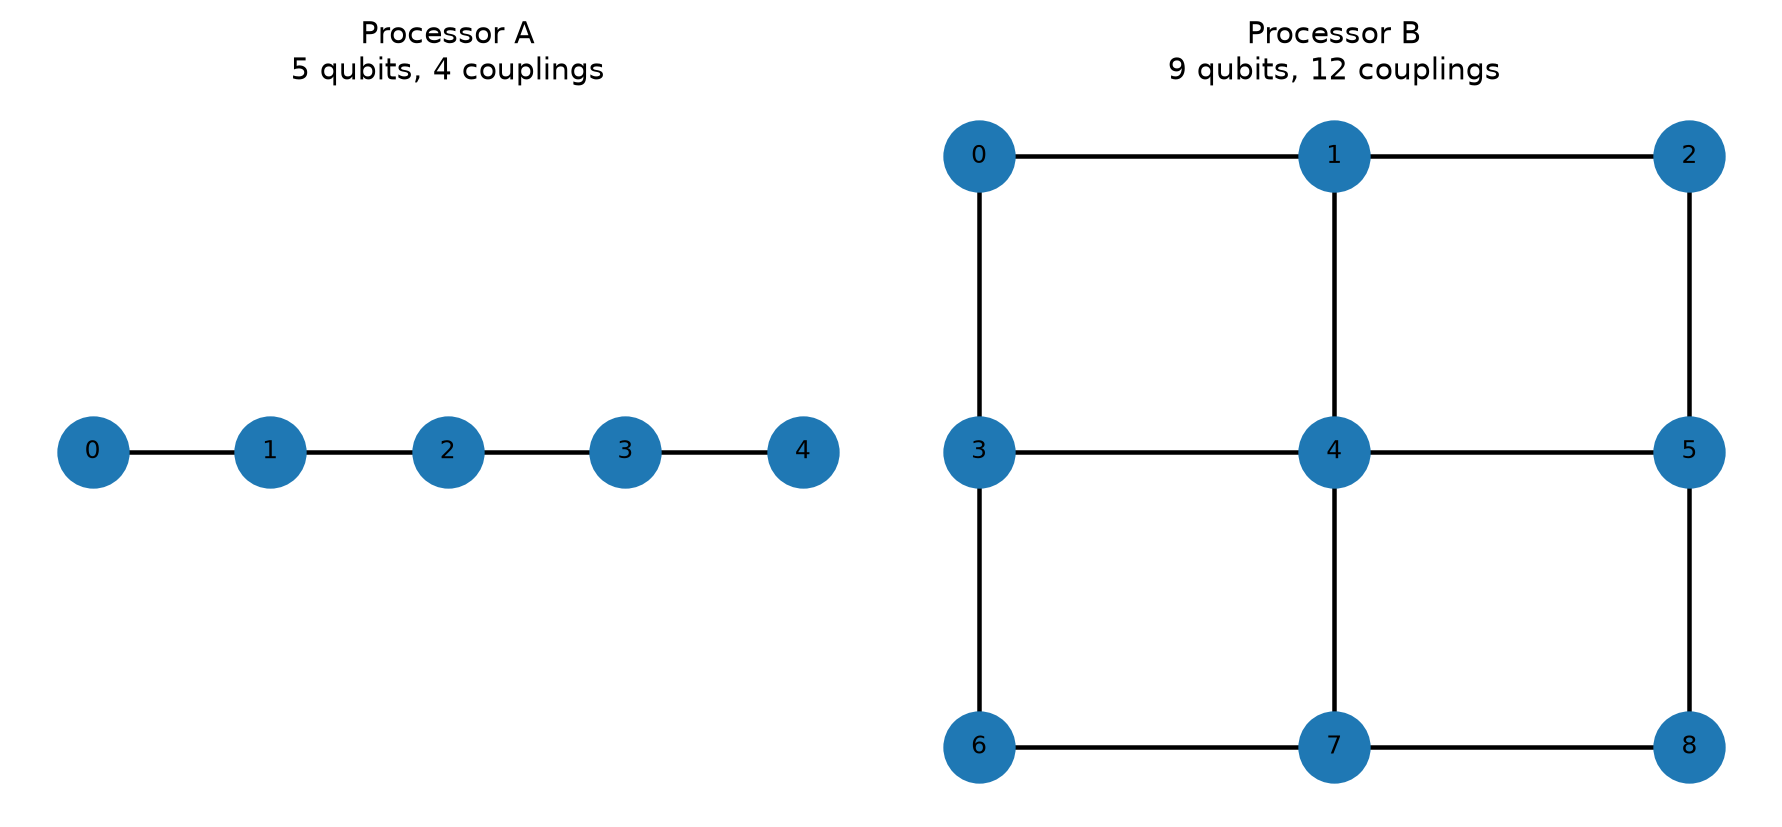

### Depth / CX / routing comparison

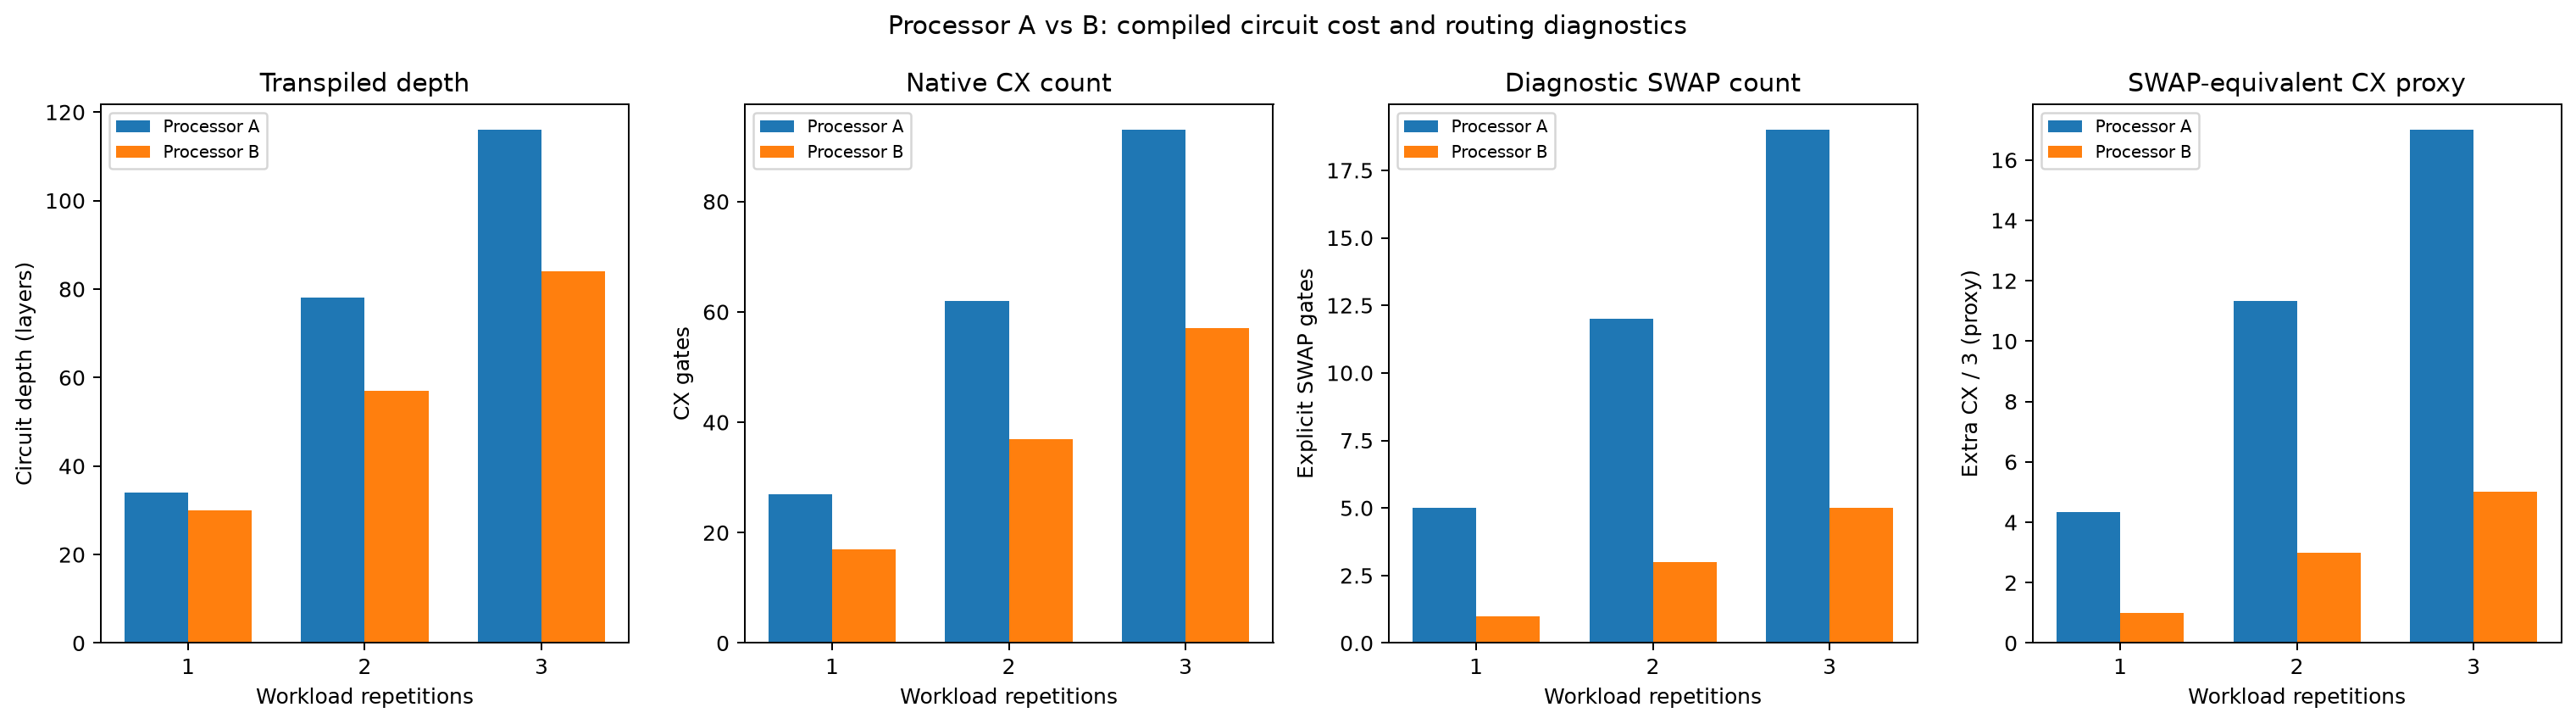

### Distribution fidelity and observable error

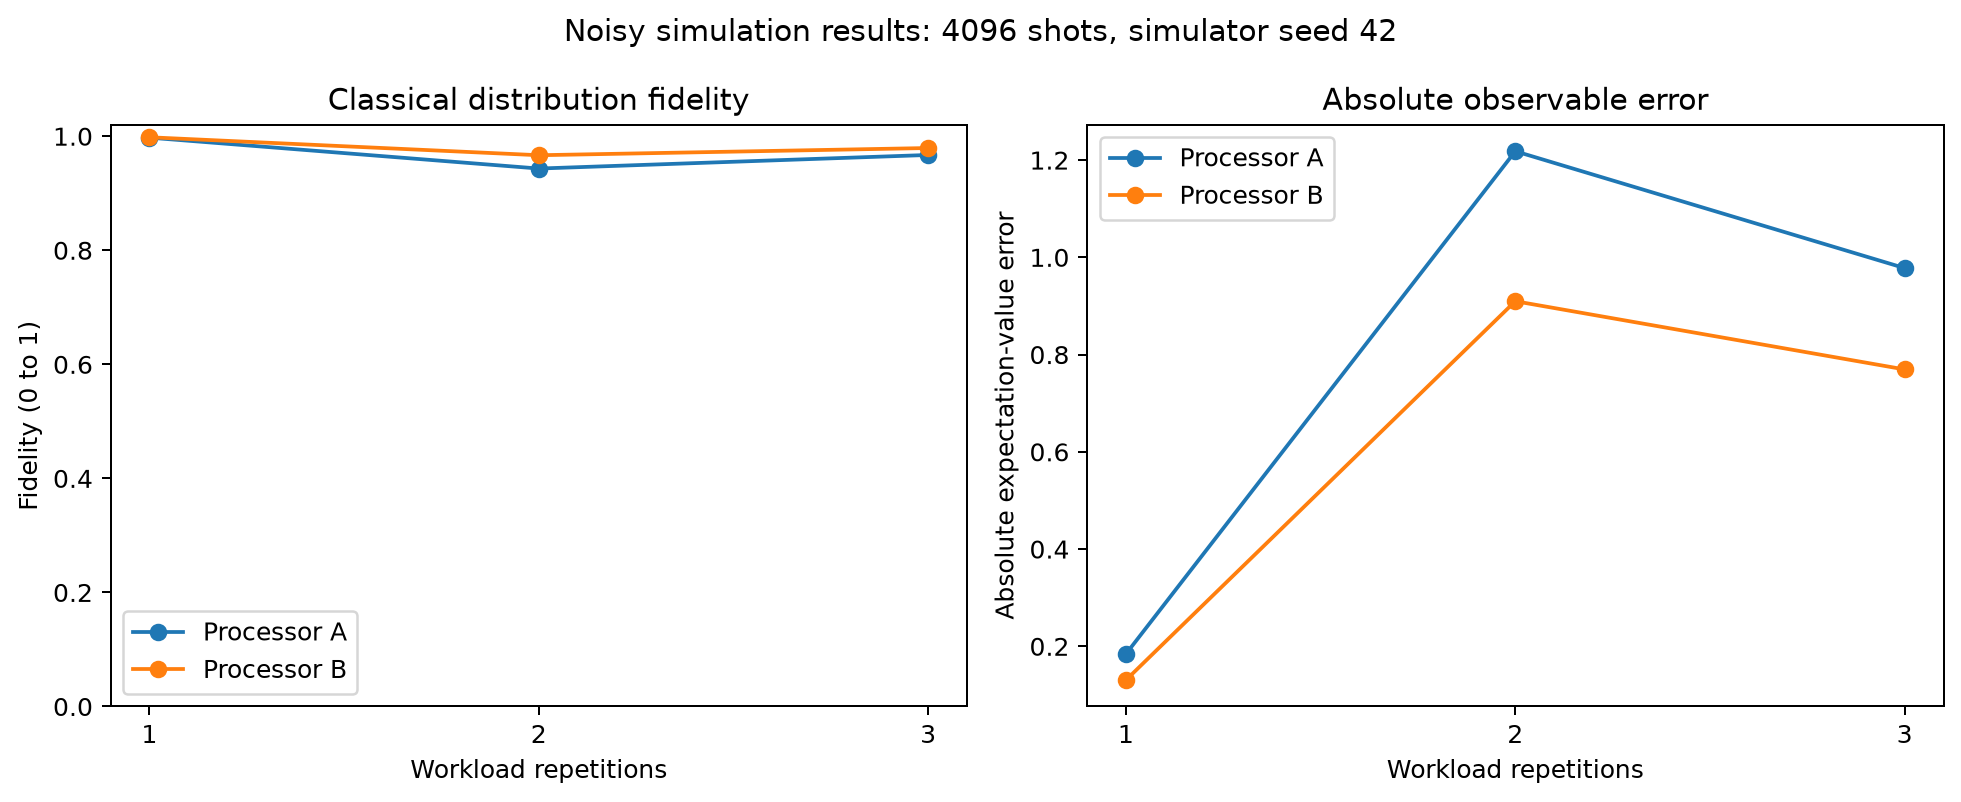

In [8]:
from scripts.analyze_quantum_results import run_analysis

analysis_outputs = run_analysis(
    metrics_csv=metrics_csv,
    processors_dir=REPO_ROOT / "processors",
    output_root=REPO_ROOT,
)
comparison_path = REPO_ROOT / "results" / "tables" / "processor_A_vs_B.csv"
comparison_frame = pd.read_csv(comparison_path)
display(comparison_frame)

for label, key in (
    ("Coupling maps", "coupling_maps"),
    ("Depth / CX / routing comparison", "depth_cx_swap_comparison"),
    ("Distribution fidelity and observable error", "fidelity_error_comparison"),
):
    display(Markdown(f"### {label}"))
    display(Image(filename=analysis_outputs[key]))

## 9. Evidence inventory and interpretation

In [9]:
artifact_paths = [
    REPO_ROOT / "data" / "raw" / "quantum_metrics.csv",
    REPO_ROOT / "data" / "raw" / "quantum_counts.json",
    REPO_ROOT / "results" / "logs" / "quantum_run_manifest.json",
    REPO_ROOT / "data" / "processed" / "quantum_summary.csv",
    REPO_ROOT / "results" / "tables" / "processor_A_vs_B.csv",
    REPO_ROOT / "results" / "figures" / "coupling_maps.png",
    REPO_ROOT / "results" / "figures" / "depth_cx_swap_comparison.png",
    REPO_ROOT / "results" / "figures" / "noisy_fidelity_by_reps.png",
]
artifact_rows = []
for path in artifact_paths:
    artifact_rows.append({
        "path": path.relative_to(REPO_ROOT).as_posix(),
        "exists": path.is_file(),
        "size_bytes": path.stat().st_size if path.is_file() else None,
    })
assert all(row["exists"] and row["size_bytes"] > 0 for row in artifact_rows)
display(pd.DataFrame(artifact_rows))

for reps in (1, 2, 3):
    a = quantum_frame[(quantum_frame.processor_id == "A") & (quantum_frame.reps == reps)].iloc[0]
    b = quantum_frame[(quantum_frame.processor_id == "B") & (quantum_frame.reps == reps)].iloc[0]
    print(
        f"reps={reps}: B-A depth={int(b.transpiled_depth-a.transpiled_depth)}, "
        f"B-A CX={int(b.native_cx_count-a.native_cx_count)}, "
        f"B-A distribution fidelity={b.distribution_fidelity-a.distribution_fidelity:.6f}"
    )

print(
    "Interpretation boundary: Processor B also has 9 physical qubits versus 5 on A, "
    "so these results compare complete architecture packages, not connectivity alone. "
    "The noise is synthetic; this is simulation evidence, not measured hardware performance. "
    "The workload is not an implementation of ECDH or ML-KEM."
)

,path,exists,size_bytes
0,data/raw/quantum_metrics.csv,True,4318
1,data/raw/quantum_counts.json,True,13909
2,results/logs/quantum_run_manifest.json,True,7907
3,data/processed/quantum_summary.csv,True,2598
4,results/tables/processor_A_vs_B.csv,True,1411
5,results/figures/coupling_maps.png,True,34790
6,results/figures/depth_cx_swap_comparison.png,True,120007
7,results/figures/noisy_fidelity_by_reps.png,True,108124


reps=1: B-A depth=-4, B-A CX=-10, B-A distribution fidelity=0.000675
reps=2: B-A depth=-21, B-A CX=-25, B-A distribution fidelity=0.023360
reps=3: B-A depth=-32, B-A CX=-36, B-A distribution fidelity=0.012180
Interpretation boundary: Processor B also has 9 physical qubits versus 5 on A, so these results compare complete architecture packages, not connectivity alone. The noise is synthetic; this is simulation evidence, not measured hardware performance. The workload is not an implementation of ECDH or ML-KEM.
